# Credit Risk Prediction by Ritika Kumari Tulsyan ---

## 1. Project Objective

The objective of this project is to build a credit-risk classification
model that distinguishes between **Good Credit** and **Bad Credit**
applicants.

**Business problem:** A bank receives loan applications. Some applicants will repay ("Good"), some will default ("Bad").
Approving a bad customer is far more expensive than rejecting a good one. Can we use data to predict who is risky?


The analysis compares **Logistic Regression** and **Linear Discriminant
Analysis (LDA)** and evaluates how changing the Logistic Regression
classification threshold affects the trade-off between overall accuracy
and Bad Credit detection.

------------------------------------------------------------------------

## 2. Data and Modeling Approach

-   **Dataset:** German Credit dataset
-   **Observations:** 1,000
-   **Predictor variables:** 20 original credit-related features
-   **Train-test split:** 80:20
-   **Training observations:** 800
-   **Test observations:** 200
-   **Class imbalance:** Addressed using SMOTE on the training data only
-   **Numerical variables:** Standardized
-   **Categorical variables:** One-hot encoded
-   **Target leakage:** Checked and excluded
-   **Models evaluated:**
    -   Logistic Regression
    -   Linear Discriminant Analysis (LDA)
------------------------------------------------------------------------


# Step 1 — Data Extraction and Dataset Understanding

## Objective

The first step of the credit-risk analysis is to obtain the German Credit dataset and understand its structure before performing any cleaning or modelling.

We use the **UCI Statlog German Credit dataset**.

The dataset contains information about applicants such as:

- Checking account status
- Credit history
- Loan purpose
- Credit amount
- Savings status
- Employment
- Loan duration
- Installment rate
- Age
- Housing
- Existing credits
- Job
- Number of dependents
- Telephone ownership
- Foreign worker status

### Target Variable

The target variable represents credit risk:

- `0` = Good Credit
- `1` = Bad Credit



In [8]:
# ============================================================
# STEP 1: DATA EXTRACTION
# ============================================================

# Import the libraries needed for data analysis, visualization and machine learning.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Set display options so we can inspect the dataset more easily.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Fix randomization so model results are reproducible.
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


In [9]:
# Public source of the German Credit dataset
DATA_URL = "https://raw.githubusercontent.com/quinfer/fin510-colab-notebooks/main/labs/german_credit.csv"

print("Data source defined.")

Data source defined.


In [10]:
# Read the CSV file into a pandas DataFrame.
# At this stage we are only extracting the data.
# No cleaning or transformation is performed.

df = pd.read_csv(DATA_URL)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [11]:
# Check the number of observations and variables
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1000
Number of columns: 21


In [12]:
# Display the first five observations to verify that
# the dataset has been loaded correctly.

display(df.head())

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property_magnitude,age,other_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,defaulted
0,A11,6.0,A34,A43,1169.0,A65,A75,4.0,A93,A101,4.0,A121,67.0,A143,A152,2.0,A173,1.0,A192,A201,0
1,A12,48.0,A32,A43,5951.0,A61,A73,2.0,A92,A101,2.0,A121,22.0,A143,A152,1.0,A173,1.0,A191,A201,1
2,A14,12.0,A34,A46,2096.0,A61,A74,2.0,A93,A101,3.0,A121,49.0,A143,A152,1.0,A172,2.0,A191,A201,0
3,A11,42.0,A32,A42,7882.0,A61,A74,2.0,A93,A103,4.0,A122,45.0,A143,A153,1.0,A173,2.0,A191,A201,0
4,A11,24.0,A33,A40,4870.0,A61,A73,3.0,A93,A101,4.0,A124,53.0,A143,A153,2.0,A173,2.0,A191,A201,1


In [13]:
# List all variables available in the raw dataset.
# We are NOT deciding which variables are important yet.

print("Variables in the dataset:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Variables in the dataset:
1. checking_status
2. duration
3. credit_history
4. purpose
5. credit_amount
6. savings_status
7. employment
8. installment_rate
9. personal_status
10. other_parties
11. residence_since
12. property_magnitude
13. age
14. other_plans
15. housing
16. existing_credits
17. job
18. num_dependents
19. own_telephone
20. foreign_worker
21. defaulted


In [14]:
# The target variable for this project is 'defaulted'.
# We only confirm its presence here.
# Target analysis will be performed in the next stages.

TARGET = "defaulted"

if TARGET in df.columns:
    print(f"Target variable '{TARGET}' is present.")
else:
    print(f"ERROR: Target variable '{TARGET}' was not found.")

Target variable 'defaulted' is present.


In [15]:
# 2.1 Size and data types
print("Rows, Columns:", df.shape)
print("\nData types:")
print(df.dtypes.value_counts())
df.info()

Rows, Columns: (1000, 21)

Data types:
object     13
float64     7
int64       1
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   checking_status     1000 non-null   object 
 1   duration            1000 non-null   float64
 2   credit_history      1000 non-null   object 
 3   purpose             1000 non-null   object 
 4   credit_amount       1000 non-null   float64
 5   savings_status      1000 non-null   object 
 6   employment          1000 non-null   object 
 7   installment_rate    1000 non-null   float64
 8   personal_status     1000 non-null   object 
 9   other_parties       1000 non-null   object 
 10  residence_since     1000 non-null   float64
 11  property_magnitude  1000 non-null   object 
 12  age                 1000 non-null   float64
 13  other_plans         1000 non-null   object 
 14

In [16]:
# Save the extracted raw dataset locally.
# This preserves the original extracted data before any
# cleaning, feature engineering, or modelling.

df.to_csv("german_credit_raw.csv", index=False)

print("Raw dataset saved as: german_credit_raw.csv")

Raw dataset saved as: german_credit_raw.csv


### Interpretation:  
The German Credit dataset was successfully extracted and loaded into a pandas DataFrame. The dataset contains 1,000 observations and 21 variables, including the binary target variable defaulted. No transformations or predictor-selection decisions have been made at this stage. The raw dataset has also been saved locally to preserve the original extracted data.

In [17]:
# Check the number of observations and variables.
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Check whether each variable is numeric or categorical.
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

# Find columns containing missing values.
print("\nMissing values:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

# Count duplicate records.
print("\nDuplicate rows:", df.duplicated().sum())

# Count unique values to understand categorical variables.
print("\nUnique values:")
display(df.nunique().sort_values().to_frame("unique_count"))

Rows: 1000
Columns: 21

Data types:


,dtype
checking_status,object
duration,float64
credit_history,object
purpose,object
credit_amount,float64
savings_status,object
employment,object
installment_rate,float64
personal_status,object
other_parties,object



Missing values:


,missing_count



Duplicate rows: 0

Unique values:


,unique_count
defaulted,2
own_telephone,2
num_dependents,2
foreign_worker,2
housing,3
other_plans,3
other_parties,3
job,4
existing_credits,4
property_magnitude,4


In [18]:
# Identify numerical variables
numeric_features = df.select_dtypes(include=np.number).columns.tolist()

# Identify categorical variables
categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical Variables:")
print(numeric_features)

print("\nCategorical Variables:")
print(categorical_features)

Numerical Variables:
['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents', 'defaulted']

Categorical Variables:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


In [19]:
# Create a readable label for charts and business interpretation.
df["credit_risk"] = df["defaulted"].map({0: "Good", 1: "Bad"})

# Create the binary target used by the ML models.
df["default"] = df["defaulted"].astype(int)

# Check the target distribution.
print(df["credit_risk"].value_counts())

# Convert counts into percentages to understand class balance.
display(
    df["credit_risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("percentage")
)

credit_risk
Good    700
Bad     300
Name: count, dtype: int64


,percentage
credit_risk,
Good,70.0
Bad,30.0


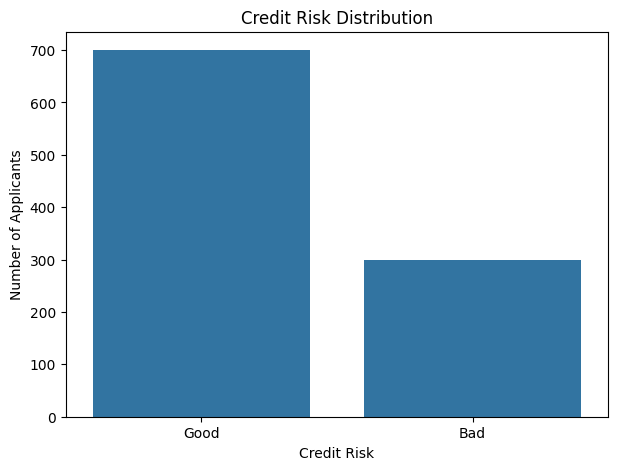

In [20]:
# Visualize the number of good- and bad-risk observations.
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="credit_risk")
plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Applicants")
plt.show()

In [21]:
# Statistical summary of numerical variables
display(df[numeric_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0
defaulted,1000.0,0.300,0.458487,0.0,0.0,0.0,1.00,1.0


<Axes: >

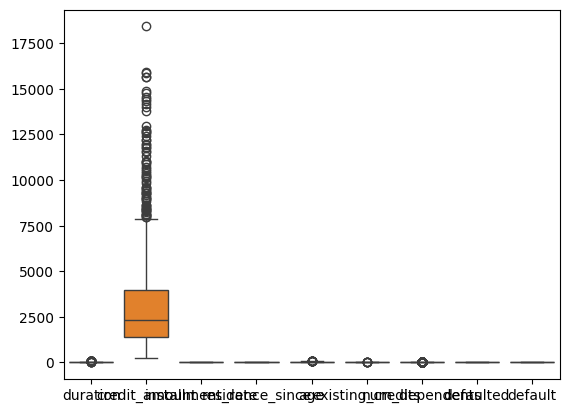

In [22]:
# Compare loan amounts across good- and bad-risk groups.
sns.boxplot(data=df)

In [23]:
df.skew(numeric_only = True)

duration            1.094184
credit_amount       1.949628
installment_rate   -0.531348
residence_since    -0.272570
age                 1.020739
existing_credits    1.272576
num_dependents      1.909445
defaulted           0.874183
default             0.874183
dtype: float64

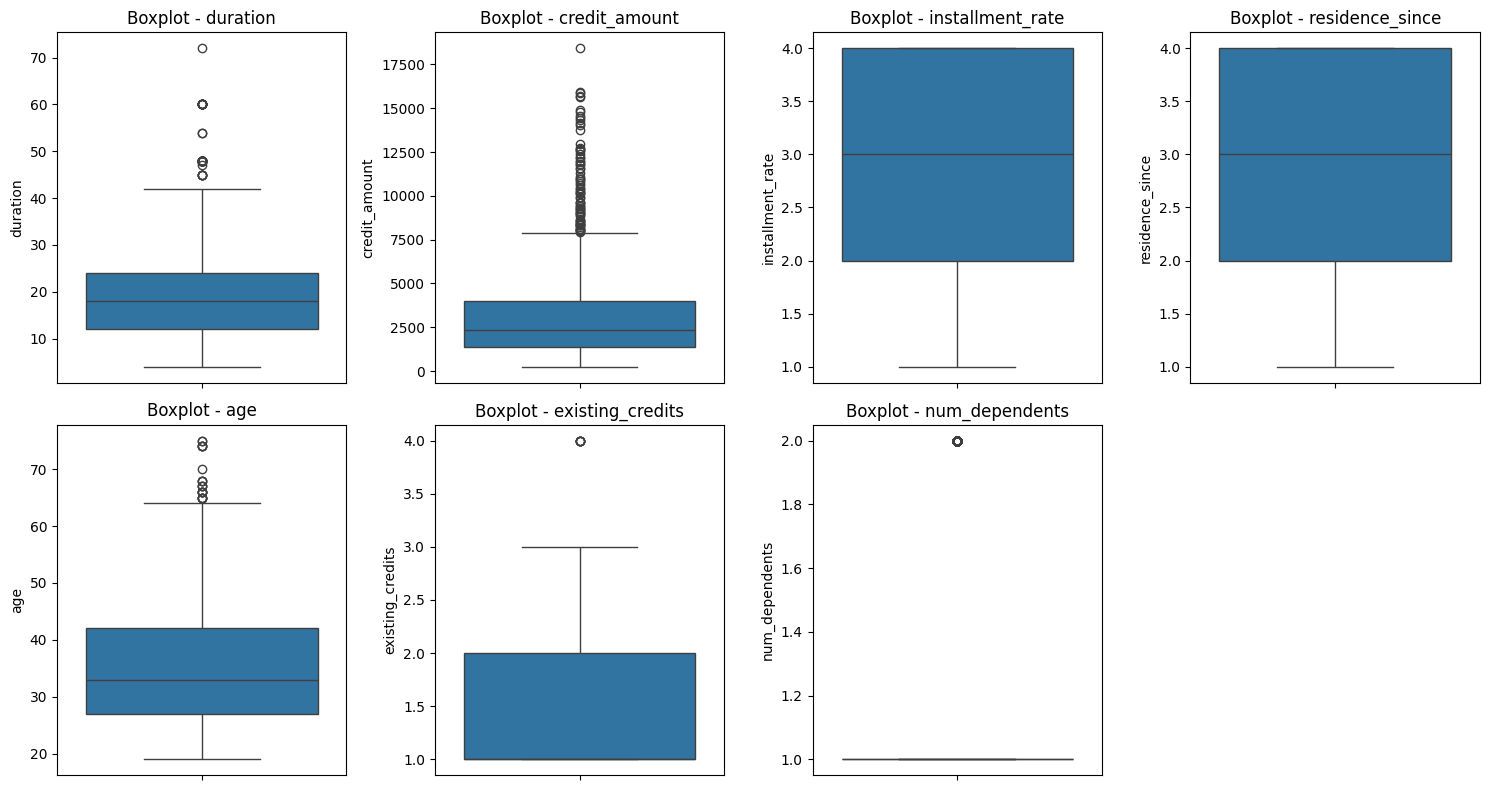

In [35]:
outlier_vars = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "num_dependents"
]

plt.figure(figsize=(15, 8))

for i, col in enumerate(outlier_vars, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot - {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

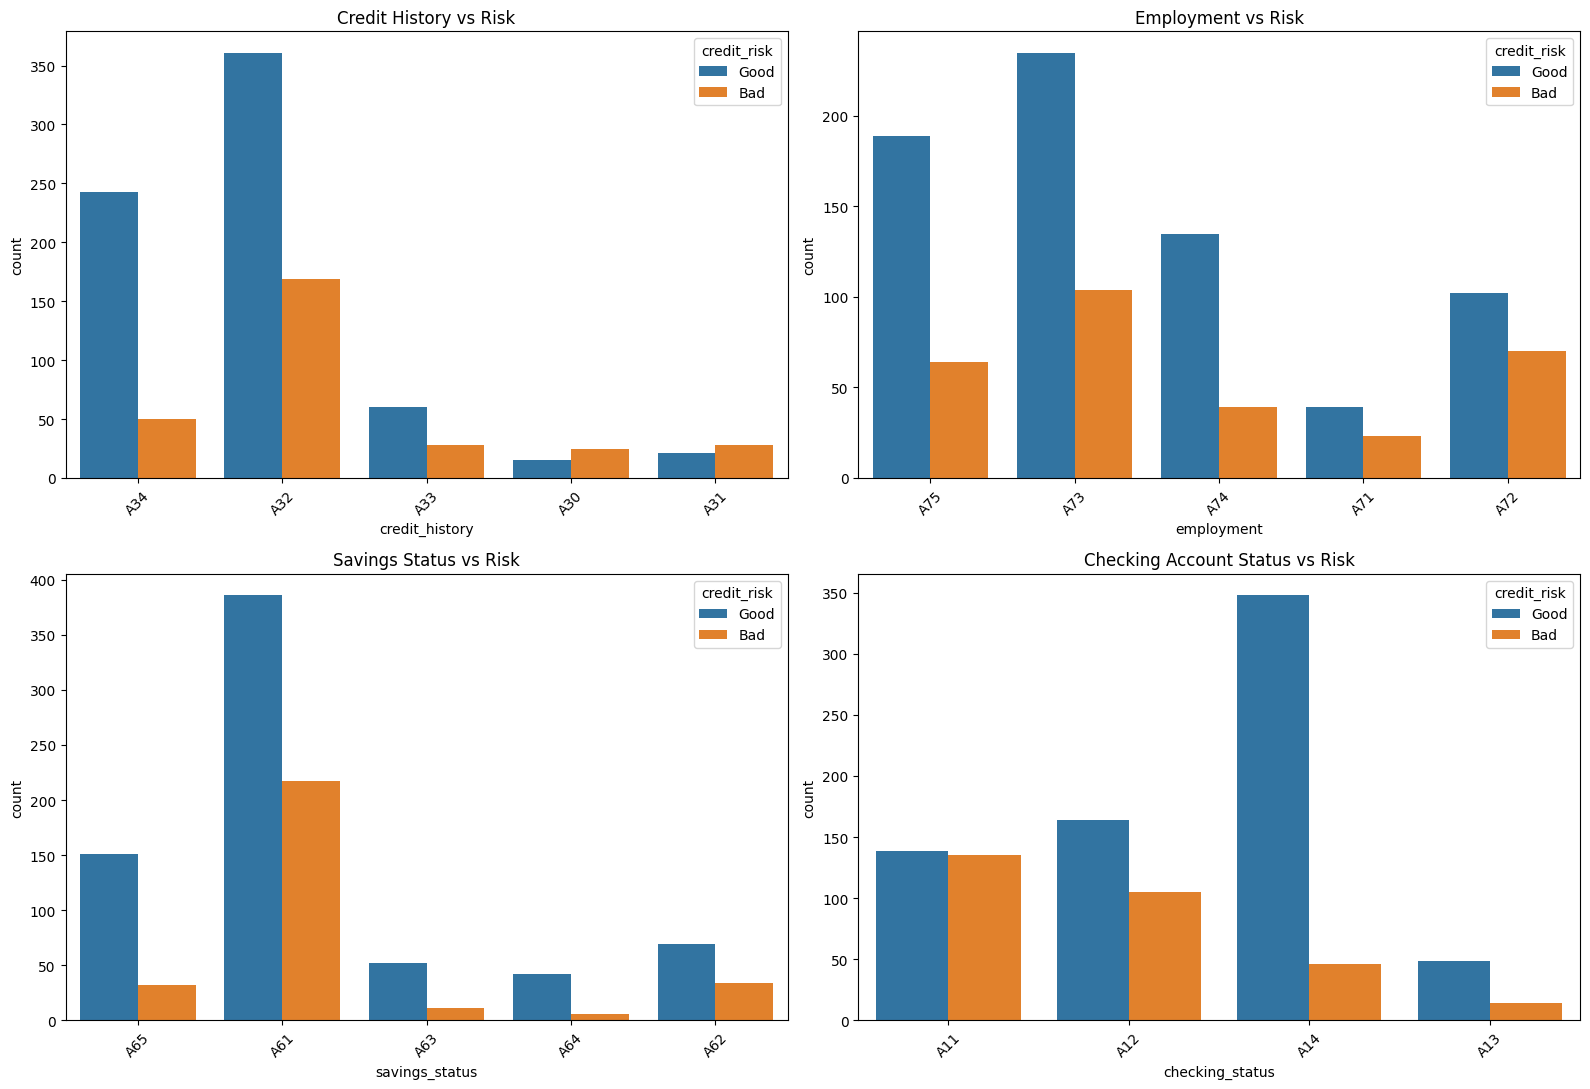

In [28]:
# Compare major categorical variables against the target.
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Credit history may provide information about past repayment behaviour.
sns.countplot(data=df, x="credit_history", hue="credit_risk", ax=axes[0, 0])
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].set_title("Credit History vs Risk")

# Employment may provide information about financial stability.
sns.countplot(data=df, x="employment", hue="credit_risk", ax=axes[0, 1])
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].set_title("Employment vs Risk")

# Savings status may indicate financial cushion.
sns.countplot(data=df, x="savings_status", hue="credit_risk", ax=axes[1, 0])
axes[1, 0].tick_params(axis="x", rotation=45)
axes[1, 0].set_title("Savings Status vs Risk")

# Checking account status may provide additional risk information.
sns.countplot(data=df, x="checking_status", hue="credit_risk", ax=axes[1, 1])
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].set_title("Checking Account Status vs Risk")

plt.tight_layout()
plt.show()

In [30]:
# ============================================================
# STEP 5 — FEATURE ENGINEERING
# ============================================================

# 1. Log transformation of credit amount
df["log_credit_amount"] = np.log1p(df["credit_amount"])

# 2. Create loan duration categories
df["duration_band"] = pd.cut(
    df["duration"],
    bins=[0, 12, 24, 48, np.inf],
    labels=["Short", "Medium", "Long", "Very Long"]
)

# 3. Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 40, 60, np.inf],
    labels=["Young", "Adult", "Middle_Aged", "Senior"]
)

# Display newly created features
display(
    df[
        [
            "credit_amount",
            "log_credit_amount",
            "duration",
            "duration_band",
            "age",
            "age_group"
        ]
    ].head(10)
)

,credit_amount,log_credit_amount,duration,duration_band,age,age_group
0,1169.0,7.064759,6.0,Short,67.0,Senior
1,5951.0,8.691483,48.0,Long,22.0,Young
2,2096.0,7.648263,12.0,Short,49.0,Middle_Aged
3,7882.0,8.972464,42.0,Long,45.0,Middle_Aged
4,4870.0,8.491055,24.0,Medium,53.0,Middle_Aged
5,9055.0,9.111183,36.0,Long,35.0,Adult
6,2835.0,7.950150,24.0,Medium,53.0,Middle_Aged
7,6948.0,8.846353,36.0,Long,35.0,Adult
8,3059.0,8.026170,12.0,Short,61.0,Senior
9,5234.0,8.563122,30.0,Long,28.0,Adult


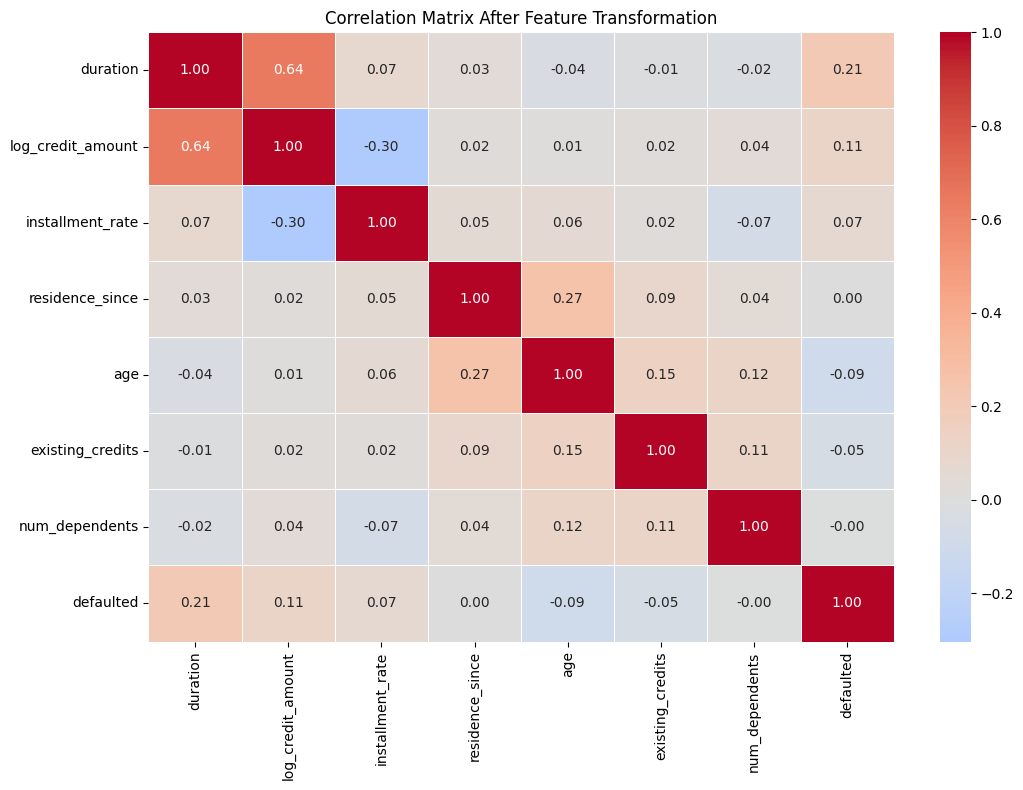

In [31]:
# ============================================================
# STEP 6 — CORRELATION MATRIX
# ============================================================

# Use log-transformed credit amount instead of original
# credit_amount for correlation analysis
corr_cols = [
    "duration",
    "log_credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "num_dependents",
    "defaulted"
]

# Calculate correlation matrix
corr_matrix = df[corr_cols].corr()

# Plot correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Matrix After Feature Transformation")
plt.tight_layout()
plt.show()

# Interpretation of Correlation Matrix

- The correlation matrix shows the linear relationships between the numerical variables and the target variable `defaulted`.

- **Loan duration (`duration`)** has the strongest positive correlation with credit risk (**0.21**). This indicates that longer loan durations are weakly associated with a higher likelihood of bad credit.

- **Log-transformed credit amount (`log_credit_amount`)** has a weak positive correlation with `defaulted` (**0.11**), suggesting that larger credit amounts are slightly associated with higher credit risk.

- **Installment rate** has a very weak positive correlation with credit risk (**0.07**), indicating a limited linear relationship.

- **Age** has a weak negative correlation with `defaulted` (**-0.09**), suggesting that older applicants tend to have slightly lower observed credit risk in this dataset.

- `residence_since`, `existing_credits`, and `num_dependents` show very weak or almost zero linear correlations with the target. However, this does **not** imply that these variables are useless for prediction because relationships may be nonlinear or influenced by interactions with other variables.

## Multicollinearity Observation

- The highest correlation among the predictor variables is between `duration` and `log_credit_amount` (**0.64**), indicating a moderate positive relationship.
- The remaining predictor correlations are relatively low.
- Therefore, there is no obvious severe pairwise multicollinearity among the numerical predictors based on the correlation matrix.

## Overall Interpretation

The correlation analysis suggests that **credit risk is not strongly explained by any single numerical variable**. Loan duration and credit amount show the most noticeable relationships with the target, but their correlations remain relatively weak. Therefore, both numerical and categorical variables should be considered in the predictive models.

> **Important:** Correlation measures only linear relationships. A low correlation with `defaulted` does not necessarily mean that a variable has no predictive value.

### Managerial Insight

Credit-risk assessment should not rely on a single numerical factor such as loan amount or duration. A combination of **loan characteristics, credit history, account status, employment, savings, and applicant characteristics** should be considered when evaluating credit risk.

In [33]:
# ============================================================
# STEP 7 — CORRECT FEATURE AND TARGET SEPARATION
# ============================================================

# Target variable
y = df["defaulted"]

# IMPORTANT: credit_risk is created FROM the target for EDA/charting.
# It must NOT be used as a model predictor because it causes target leakage.
# default is also excluded in case it exists in the dataframe.
X = df.drop(
    columns=["defaulted", "credit_risk", "default"],
    errors="ignore"
)

print("Target:", y.name)
print("Features shape:", X.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget-derived columns remaining in X:")
print([
    col for col in X.columns
    if col.lower() in ["defaulted", "default", "credit_risk"]
])


Target: defaulted
Features shape: (1000, 23)

Target distribution:
defaulted
0    700
1    300
Name: count, dtype: int64

Target-derived columns remaining in X:
[]


In [34]:
# ============================================================
# STEP 7.2 — TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set: (800, 23)
Testing set: (200, 23)

Training target distribution:
defaulted
0    560
1    240
Name: count, dtype: int64

Testing target distribution:
defaulted
0    140
1     60
Name: count, dtype: int64


In [35]:
# ============================================================
# STEP 8 — PREPROCESSING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE

numeric_features = [
    "duration",
    "log_credit_amount",
    "installment_rate",
    "residence_since",
    "age",
    "existing_credits",
    "num_dependents"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            drop="first"
        ), categorical_features)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (800, 799)
Testing shape: (200, 799)


In [36]:
# ============================================================
# STEP 8.5 — APPLY SMOTE ONLY TO TRAINING DATA
# ============================================================

smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
defaulted
0    560
1    240
Name: count, dtype: int64

After SMOTE:
defaulted
1    560
0    560
Name: count, dtype: int64


In [37]:
# ============================================================
# STEP 9 — LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_smote,
    y_train_smote
)

y_pred_logistic = logistic_model.predict(X_test_processed)

y_prob_logistic = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Logistic Regression Performance")
print("=" * 40)

print(f"Accuracy  : {accuracy_score(y_test, y_pred_logistic):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_logistic):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_logistic):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_logistic):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_logistic):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=["Good Credit", "Bad Credit"]
    )
)

Logistic Regression Performance
Accuracy  : 0.7500
Precision : 0.5694
Recall    : 0.6833
F1 Score  : 0.6212
ROC-AUC   : 0.7789

Classification Report:
              precision    recall  f1-score   support

 Good Credit       0.85      0.78      0.81       140
  Bad Credit       0.57      0.68      0.62        60

    accuracy                           0.75       200
   macro avg       0.71      0.73      0.72       200
weighted avg       0.77      0.75      0.76       200



In [38]:
# ============================================================
# DECISION MATRIX — LOGISTIC REGRESSION
# ============================================================

from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_test, y_pred_logistic)

tn, fp, fn, tp = cm.ravel()

decision_matrix = pd.DataFrame(
    [
        [tn, fp],
        [fn, tp]
    ],
    index=["Actual Good Credit", "Actual Bad Credit"],
    columns=["Predicted Good Credit", "Predicted Bad Credit"]
)

print("\nDecision Matrix")
print("=" * 50)
display(decision_matrix)

print("\nBusiness Interpretation")
print("=" * 50)
print(f"TN - Good correctly identified as Good   : {tn}")
print(f"FP - Good incorrectly identified as Bad  : {fp}")
print(f"FN - Bad incorrectly identified as Good  : {fn}")
print(f"TP - Bad correctly identified as Bad     : {tp}")

print("\nCredit Risk Interpretation:")
print(f"False Negatives (Bad → Good): {fn}")
print("These cases represent potentially risky customers who may be approved.")


Decision Matrix


,Predicted Good Credit,Predicted Bad Credit
Actual Good Credit,109,31
Actual Bad Credit,19,41



Business Interpretation
TN - Good correctly identified as Good   : 109
FP - Good incorrectly identified as Bad  : 31
FN - Bad incorrectly identified as Good  : 19
TP - Bad correctly identified as Bad     : 41

Credit Risk Interpretation:
False Negatives (Bad → Good): 19
These cases represent potentially risky customers who may be approved.


In [39]:
# ============================================================
# STEP 10 — LINEAR DISCRIMINANT ANALYSIS (LDA)
# ============================================================

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# ------------------------------------------------------------
# Convert SMOTE training data from sparse to dense
# LDA requires dense input
# ------------------------------------------------------------

if hasattr(X_train_smote, "toarray"):
    X_train_lda = X_train_smote.toarray()
else:
    X_train_lda = X_train_smote

# Convert test data as well
if hasattr(X_test_processed, "toarray"):
    X_test_lda = X_test_processed.toarray()
else:
    X_test_lda = X_test_processed

print("LDA training shape :", X_train_lda.shape)
print("LDA test shape     :", X_test_lda.shape)

# ------------------------------------------------------------
# Create and train LDA
# ------------------------------------------------------------

lda_model = LinearDiscriminantAnalysis()

lda_model.fit(
    X_train_lda,
    y_train_smote
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

y_pred_lda = lda_model.predict(X_test_lda)

# Probability of Bad Credit
y_prob_lda = lda_model.predict_proba(
    X_test_lda
)[:, 1]

# ------------------------------------------------------------
# LDA PERFORMANCE
# ------------------------------------------------------------

print("\nLinear Discriminant Analysis Performance")
print("=" * 45)

print(f"Accuracy  : {accuracy_score(y_test, y_pred_lda):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_lda):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_lda):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_lda):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob_lda):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lda,
        target_names=["Good Credit", "Bad Credit"]
    )
)

LDA training shape : (1120, 799)
LDA test shape     : (200, 799)

Linear Discriminant Analysis Performance
Accuracy  : 0.6050
Precision : 0.3855
Recall    : 0.5333
F1 Score  : 0.4476
ROC-AUC   : 0.5905

Classification Report:
              precision    recall  f1-score   support

 Good Credit       0.76      0.64      0.69       140
  Bad Credit       0.39      0.53      0.45        60

    accuracy                           0.60       200
   macro avg       0.57      0.58      0.57       200
weighted avg       0.65      0.60      0.62       200



### Interpretation

LDA produced lower values across all evaluated classification metrics
than Logistic Regression on the same test set.

This indicates that, under the current preprocessing and modeling setup,
Logistic Regression provides stronger predictive performance for this
dataset.

In [40]:
# ============================================================
# STEP 10.1 — LDA DECISION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix

cm_lda = confusion_matrix(y_test, y_pred_lda)

tn_lda, fp_lda, fn_lda, tp_lda = cm_lda.ravel()

decision_matrix_lda = pd.DataFrame(
    [
        [tn_lda, fp_lda],
        [fn_lda, tp_lda]
    ],
    index=["Actual Good Credit", "Actual Bad Credit"],
    columns=["Predicted Good Credit", "Predicted Bad Credit"]
)

print("\nLDA Decision Matrix")
print("=" * 50)

display(decision_matrix_lda)

print("\nBusiness Interpretation")
print("=" * 50)

print(f"TN - Good → Good : {tn_lda}")
print(f"FP - Good → Bad  : {fp_lda}")
print(f"FN - Bad → Good  : {fn_lda}")
print(f"TP - Bad → Bad    : {tp_lda}")


LDA Decision Matrix


,Predicted Good Credit,Predicted Bad Credit
Actual Good Credit,89,51
Actual Bad Credit,28,32



Business Interpretation
TN - Good → Good : 89
FP - Good → Bad  : 51
FN - Bad → Good  : 28
TP - Bad → Bad    : 32


In [41]:
# ============================================================
# STEP 11 — LOGISTIC REGRESSION vs LDA
# ============================================================

comparison_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "LDA"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_lda)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_lda)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_lda)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_lda)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_logistic),
        roc_auc_score(y_test, y_prob_lda)
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(
    comparison_results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "ROC-AUC": "{:.2%}"
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,75.00%,56.94%,68.33%,62.12%,77.89%
1,LDA,60.50%,38.55%,53.33%,44.76%,59.05%


### Key Observation

Logistic Regression performed better than LDA on **all five evaluated
metrics**.

Therefore, Logistic Regression is used as the primary model for the
final evaluation, while LDA serves as the comparison model.

------------------------------------------------------------------------

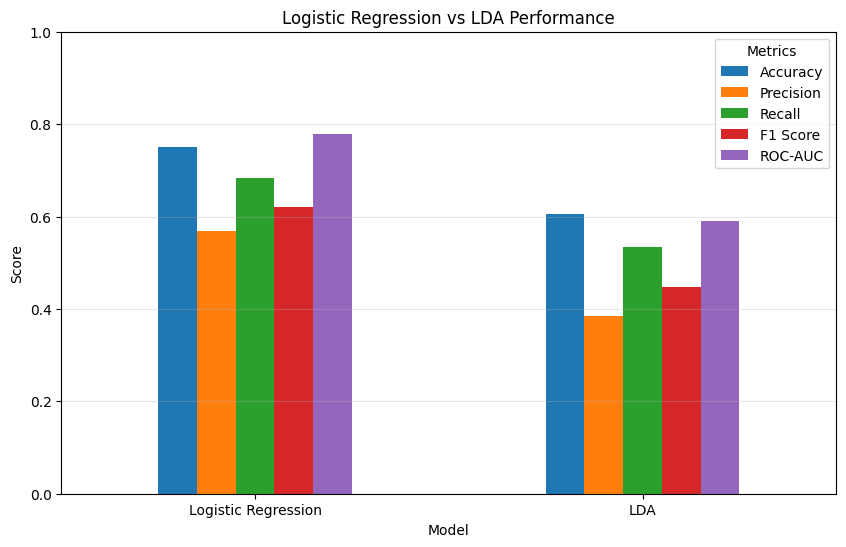

In [42]:
# ============================================================
# STEP 11.1 — PERFORMANCE COMPARISON CHART
# ============================================================

import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_plot = comparison_results.set_index("Model")[metrics]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs LDA Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)

plt.show()

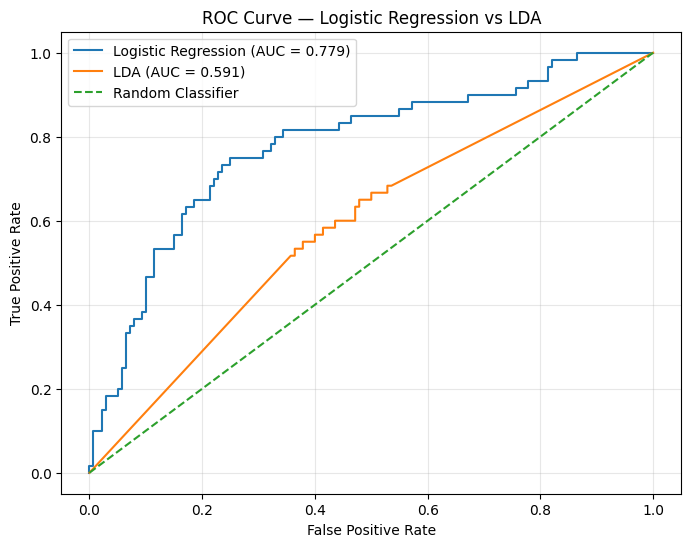

In [43]:
# ============================================================
# STEP 11.2 — ROC CURVE COMPARISON
# ============================================================

from sklearn.metrics import roc_curve

# Logistic Regression ROC
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    y_prob_logistic
)

# LDA ROC
fpr_lda, tpr_lda, _ = roc_curve(
    y_test,
    y_prob_lda
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_logistic):.3f})"
)

plt.plot(
    fpr_lda,
    tpr_lda,
    label=f"LDA (AUC = {roc_auc_score(y_test, y_prob_lda):.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression vs LDA")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [44]:
# ============================================================
# STEP 11.3 — DECISION MATRIX COMPARISON
# ============================================================

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

cm_lda = confusion_matrix(
    y_test,
    y_pred_lda
)

tn_lr, fp_lr, fn_lr, tp_lr = cm_logistic.ravel()
tn_lda, fp_lda, fn_lda, tp_lda = cm_lda.ravel()

decision_comparison = pd.DataFrame({
    "Outcome": [
        "Good → Good (TN)",
        "Good → Bad (FP)",
        "Bad → Good (FN)",
        "Bad → Bad (TP)"
    ],
    "Logistic Regression": [
        tn_lr,
        fp_lr,
        fn_lr,
        tp_lr
    ],
    "LDA": [
        tn_lda,
        fp_lda,
        fn_lda,
        tp_lda
    ]
})

print("DECISION MATRIX COMPARISON")
print("=" * 60)

display(decision_comparison)

DECISION MATRIX COMPARISON


,Outcome,Logistic Regression,LDA
0,Good → Good (TN),109,89
1,Good → Bad (FP),31,51
2,Bad → Good (FN),19,28
3,Bad → Bad (TP),41,32


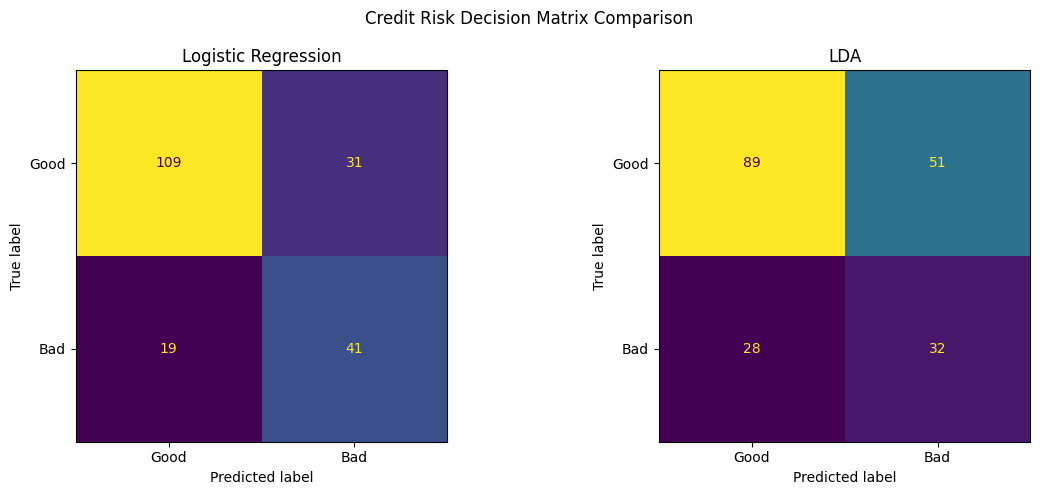

In [45]:
# ============================================================
# STEP 11.4 — CONFUSION MATRIX VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Good", "Bad"]
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("Logistic Regression")

# LDA
ConfusionMatrixDisplay(
    confusion_matrix=cm_lda,
    display_labels=["Good", "Bad"]
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("LDA")

plt.suptitle("Credit Risk Decision Matrix Comparison")
plt.tight_layout()
plt.show()

In [46]:
# ============================================================
# STEP 12.3 — MODEL SELECTION
# ============================================================

print("MODEL SELECTION")
print("=" * 60)

print("Logistic Regression Test Performance:")
print(f"Accuracy : {accuracy_score(y_test, y_pred_logistic):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_logistic):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_logistic):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_logistic):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_logistic):.4f}")

print("\nLDA Test Performance:")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lda):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lda):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_lda):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_lda):.4f}")

print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_lda):.4f}")

print("\nSelected model based on the current test-set comparison:")
print("Logistic Regression")

MODEL SELECTION
Logistic Regression Test Performance:
Accuracy : 0.7500
Precision: 0.5694
Recall   : 0.6833
F1 Score : 0.6212
ROC-AUC  : 0.7789

LDA Test Performance:
Accuracy : 0.6050
Precision: 0.3855
Recall   : 0.5333
F1 Score : 0.4476
ROC-AUC  : 0.5905

Selected model based on the current test-set comparison:
Logistic Regression


In [47]:
y_prob_logistic

array([0.41838169, 0.1228095 , 0.77563499, 0.60289998, 0.27091596,
       0.22713913, 0.31077278, 0.11725918, 0.54589504, 0.18906046,
       0.17232399, 0.49013697, 0.01751461, 0.55710072, 0.7361202 ,
       0.02332877, 0.18271764, 0.08301771, 0.05056082, 0.0284183 ,
       0.29424956, 0.30756729, 0.08167083, 0.87712499, 0.40540703,
       0.67816367, 0.0070229 , 0.34152837, 0.28832525, 0.03800486,
       0.0839579 , 0.278037  , 0.15702401, 0.72290963, 0.10703375,
       0.86398848, 0.73494084, 0.95376874, 0.20732699, 0.89367064,
       0.72589093, 0.5993323 , 0.2193322 , 0.29500588, 0.04025041,
       0.01688443, 0.93058766, 0.84386951, 0.16742878, 0.08981088,
       0.15031848, 0.10475554, 0.35401198, 0.78178669, 0.79114499,
       0.07674316, 0.03778473, 0.08847504, 0.80568879, 0.68399207,
       0.17050652, 0.79774624, 0.33186077, 0.75369499, 0.09837188,
       0.45356326, 0.01665627, 0.01982881, 0.69811814, 0.88156468,
       0.12924266, 0.81288324, 0.29939185, 0.18306783, 0.47394

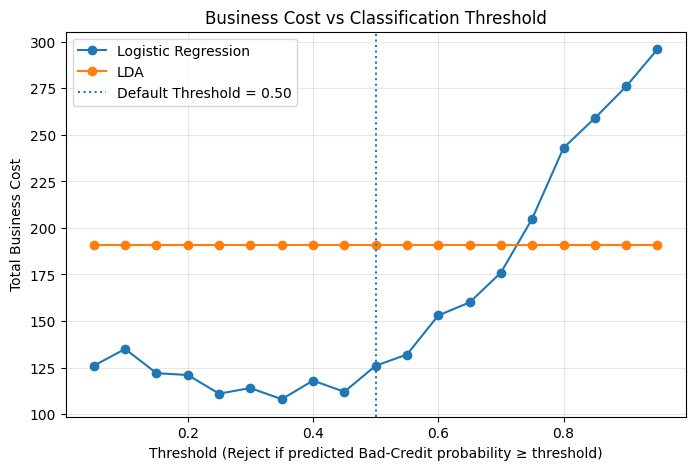


Logistic Regression
Cost at default threshold (0.50): 126
Lowest-cost threshold: 0.35
Minimum total cost: 108

LDA
Cost at default threshold (0.50): 191
Lowest-cost threshold: 0.05
Minimum total cost: 191

LOGISTIC REGRESSION — BUSINESS OUTCOME BY THRESHOLD


,Approval Rate (%),Bad Credit Caught (%),Good Credit Rejected (%),Missed Bad Customers (FN),Good Customers Rejected (FP),Total Cost
Threshold,,,,,,
0.050000,10.0,98.3,86.4,1,121,126
0.100000,20.5,90.0,75.0,6,105,135
0.150000,30.0,88.3,62.1,7,87,122
0.200000,36.5,85.0,54.3,9,76,121
0.250000,41.5,85.0,47.1,9,66,111
0.300000,46.0,81.7,42.1,11,59,114
0.350000,52.0,80.0,34.3,12,48,108
0.400000,56.0,75.0,30.7,15,43,118
0.450000,59.0,75.0,26.4,15,37,112


In [51]:
# ============================================================
# STEP 13 — BUSINESS COST / THRESHOLD ANALYSIS
# ============================================================

from sklearn.metrics import confusion_matrix

# UCI German Credit cost structure
# False Negative = Bad customer predicted as Good
# False Positive = Good customer predicted as Bad

COST_FN = 5
COST_FP = 1


def business_outcome(y_true, prob, threshold):

    # 1 = Bad Credit / Reject
    # 0 = Good Credit / Approve
    pred = (prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": round(threshold, 2),

        "Approval Rate (%)":
            round((pred == 0).mean() * 100, 1),

        "Bad Credit Caught (%)":
            round(tp / (tp + fn) * 100, 1),

        "Good Credit Rejected (%)":
            round(fp / (fp + tn) * 100, 1),

        "Missed Bad Customers (FN)": fn,

        "Good Customers Rejected (FP)": fp,

        "Total Cost":
            COST_FN * fn + COST_FP * fp
    }


# ------------------------------------------------------------
# Thresholds to evaluate
# ------------------------------------------------------------

thresholds = np.arange(0.05, 0.96, 0.05)


# ------------------------------------------------------------
# Logistic Regression and LDA
# ------------------------------------------------------------

sweep = {
    "Logistic Regression": pd.DataFrame(
        [
            business_outcome(
                y_test,
                y_prob_logistic,
                threshold
            )
            for threshold in thresholds
        ]
    ).set_index("Threshold"),

    "LDA": pd.DataFrame(
        [
            business_outcome(
                y_test,
                y_prob_lda,
                threshold
            )
            for threshold in thresholds
        ]
    ).set_index("Threshold")
}


# ------------------------------------------------------------
# Plot business cost against threshold
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

for name, table in sweep.items():

    plt.plot(
        table.index,
        table["Total Cost"],
        marker="o",
        label=name
    )

plt.axvline(
    0.50,
    linestyle=":",
    label="Default Threshold = 0.50"
)

plt.xlabel(
    "Threshold "
    "(Reject if predicted Bad-Credit probability ≥ threshold)"
)

plt.ylabel("Total Business Cost")

plt.title("Business Cost vs Classification Threshold")

plt.legend()
plt.grid(alpha=0.3)

plt.show()


# ------------------------------------------------------------
# Find minimum-cost threshold
# ------------------------------------------------------------

for name, table in sweep.items():

    best_threshold = table["Total Cost"].idxmin()
    minimum_cost = table.loc[
        best_threshold,
        "Total Cost"
    ]

    default_cost = table.loc[
        0.50,
        "Total Cost"
    ]

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        f"Cost at default threshold (0.50): "
        f"{default_cost}"
    )

    print(
        f"Lowest-cost threshold: "
        f"{best_threshold:.2f}"
    )

    print(
        f"Minimum total cost: "
        f"{minimum_cost}"
    )


# ------------------------------------------------------------
# Display Logistic Regression business table
# ------------------------------------------------------------

print("\nLOGISTIC REGRESSION — BUSINESS OUTCOME BY THRESHOLD")

display(
    sweep["Logistic Regression"].style.format({
        "Approval Rate (%)": "{:.1f}",
        "Bad Credit Caught (%)": "{:.1f}",
        "Good Credit Rejected (%)": "{:.1f}",
        "Total Cost": "{:.0f}"
    })
)

## Threshold Analysis — Business Interpretation

The threshold analysis examines how changing the classification threshold affects the trade-off between approving customers and identifying Bad-credit customers.

The model classifies an applicant as **Bad Credit (Reject)** when the predicted probability of default is greater than or equal to the selected threshold.

### Key Findings

- At a **low threshold (0.05)**, the model catches **98.3% of Bad-credit customers**, but only 10% of applicants are approved. This also results in a very high **Good-customer rejection rate of 86.4%**.
- As the threshold increases, the **approval rate increases**, but the model catches fewer Bad-credit customers.
- At the default threshold of **0.50**, the model approves **64%** of applicants and catches **68.3%** of Bad-credit customers. However, **19 Bad-credit customers are missed**, resulting in a total business cost of **126**.
- At a threshold of **0.35**, the model approves **52%** of applicants and catches **80.0%** of Bad-credit customers. The number of missed Bad-credit customers falls to **12**, while **48 Good customers are rejected**.
- The **lowest observed total cost is 108 at a threshold of 0.35**, compared with 126 at the default threshold of 0.50.

### Business Interpretation

The results demonstrate the trade-off between **risk protection and customer acceptance**. Lowering the threshold increases the ability to identify risky applicants but also causes more Good-credit customers to be rejected. Increasing the threshold improves the approval rate but increases the number of Bad-credit customers that are incorrectly approved.

Under the specified cost structure, where **missing a Bad-credit customer has a cost of 5 and rejecting a Good-credit customer has a cost of 1**, the threshold of **0.35 produces the lowest observed cost of 108** in this test-set sensitivity analysis.

### Important Note

The threshold of 0.35 should be treated as a **business sensitivity result rather than a final validated operational threshold**, because the analysis shown here uses the test set. The threshold should ideally be selected using development/CV data and then evaluated once on the untouched test set.

In [55]:
# ============================================================
# FINAL PERFORMANCE + DECISION MATRIX — THRESHOLD = 0.35
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

THRESHOLD = 0.35

# 1. Create predictions using 0.35 threshold
y_pred_035 = (y_prob_logistic >= THRESHOLD).astype(int)

# ============================================================
# 2. PERFORMANCE METRICS
# ============================================================

accuracy_035 = accuracy_score(y_test, y_pred_035)
precision_035 = precision_score(y_test, y_pred_035)
recall_035 = recall_score(y_test, y_pred_035)
f1_035 = f1_score(y_test, y_pred_035)
auc_035 = roc_auc_score(y_test, y_prob_logistic)

performance_035 = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall (Bad Credit)",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        accuracy_035,
        precision_035,
        recall_035,
        f1_035,
        auc_035
    ]
})

performance_035["Value (%)"] = (
    performance_035["Value"] * 100
).round(2)

print("PERFORMANCE MATRIX — THRESHOLD = 0.35")
print("=" * 55)

display(performance_035[["Metric", "Value (%)"]])


# ============================================================
# 3. CONFUSION / DECISION MATRIX
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_035,
    labels=[0, 1]
).ravel()

decision_matrix_035 = pd.DataFrame(
    [
        [tn, fp],
        [fn, tp]
    ],
    index=["Actual Good Credit", "Actual Bad Credit"],
    columns=["Predicted Good Credit", "Predicted Bad Credit"]
)

print("\nDECISION MATRIX — THRESHOLD = 0.35")
print("=" * 55)

display(decision_matrix_035)


# ============================================================
# 4. BUSINESS OUTCOME
# ============================================================

COST_FN = 5   # Bad Credit predicted as Good
COST_FP = 1   # Good Credit predicted as Bad

total_cost_035 = (fn * COST_FN) + (fp * COST_FP)

approval_rate_035 = (y_pred_035 == 0).mean() * 100
bad_caught_035 = recall_035 * 100

print("\nBUSINESS OUTCOME — THRESHOLD = 0.35")
print("=" * 55)

print(f"Approval Rate             : {approval_rate_035:.2f}%")
print(f"Bad Credit Caught         : {bad_caught_035:.2f}%")
print(f"Missed Bad Customers (FN) : {fn}")
print(f"Good Customers Rejected (FP): {fp}")
print(f"Total Business Cost       : {total_cost_035}")

PERFORMANCE MATRIX — THRESHOLD = 0.35


,Metric,Value (%)
0,Accuracy,70.00
1,Precision,50.00
2,Recall (Bad Credit),80.00
3,F1 Score,61.54
4,ROC-AUC,77.89



DECISION MATRIX — THRESHOLD = 0.35


,Predicted Good Credit,Predicted Bad Credit
Actual Good Credit,92,48
Actual Bad Credit,12,48



BUSINESS OUTCOME — THRESHOLD = 0.35
Approval Rate             : 52.00%
Bad Credit Caught         : 80.00%
Missed Bad Customers (FN) : 12
Good Customers Rejected (FP): 48
Total Business Cost       : 108


# Logistic Regression --- Test Performance at 0.50 Threshold

  Metric        Logistic Regression
  ----------- ---------------------
  Accuracy               **75.00%**
  Precision              **56.94%**
  Recall                 **68.33%**
  F1 Score               **62.12%**
  ROC-AUC                **77.89%**

### Interpretation

Logistic Regression correctly classified **75%** of the test
observations.

The **68.33% recall for Bad Credit** means that the model identified
approximately two-thirds of the genuinely Bad Credit applicants in the
test set.

The **ROC-AUC of 77.89%** indicates useful discriminatory ability
between Good Credit and Bad Credit cases.

------------------------------------------------------------------------


## Interpretation — Threshold = 0.35

At a threshold of **0.35**, the Logistic Regression model achieves an
**accuracy of 70.00%**, **precision of 50.00%**, **Bad-Credit recall of 80.00%**,
and an **F1-score of 61.54%**. The **ROC-AUC remains 77.89%** because it is
based on predicted probabilities rather than a single classification threshold.

### Decision Matrix Interpretation

- **92 Good-credit customers** are correctly approved (TN).
- **48 Good-credit customers** are incorrectly rejected (FP).
- **12 Bad-credit customers** are incorrectly approved (FN).
- **48 Bad-credit customers** are correctly rejected (TP).

Thus, the model correctly identifies **80% of the Bad-credit customers**, while
missing **12 risky customers**.

### Business Interpretation

At a threshold of 0.35, the model approves **52% of applicants** and rejects
48%. This increases risk detection compared with the default 0.50 threshold:

- Bad-credit recall increases from **68.33% to 80.00%**.
- Missed Bad-credit customers decrease from **19 to 12**.
- Approval rate decreases from **64% to 52%**.
- Good-credit rejections increase from **31 to 48**.

Using the specified cost structure, where a missed Bad-credit customer has a
cost of **5** and an incorrectly rejected Good-credit customer has a cost of
**1**, the total business cost is:

**Total Cost = (12 × 5) + (48 × 1) = 108**

Therefore, the 0.35 threshold places greater emphasis on **reducing the risk
of approving Bad-credit customers**, while accepting more false rejections of
Good-credit customers.

> **Note:** The threshold of 0.35 produced the lowest observed business cost
> in this test-set sensitivity analysis.


------------------------------------------------------------------------

# 7. Business Interpretation of Classification Errors

## False Negative

**Actual Bad Credit → Predicted Good Credit**

This is an important credit-risk error because an applicant who is
actually risky may be treated as a Good Credit applicant.

A higher Bad Credit recall helps reduce this type of error.

## False Positive

**Actual Good Credit → Predicted Bad Credit**

This means a potentially creditworthy applicant is flagged as risky.

A high number of false positives can result in:

-   unnecessary manual reviews,
-   rejection of potentially good customers,
-   reduced business opportunities.

Therefore, threshold selection involves a trade-off between **risk
detection and customer acceptance**.

------------------------------------------------------------------------

# 8. Final Threshold Interpretation

For the formal test-set evaluation, the **0.50 threshold is retained as
the baseline**.

The threshold analysis is presented as a **sensitivity/business
analysis**, rather than as a separately validated final threshold,
because the threshold comparison was performed using the test-set
results.

### At 0.50 threshold

-   Accuracy = **75.00%**
-   Precision = **56.94%**
-   Bad Credit Recall = **68.33%**
-   F1 Score = **62.12%**
-   ROC-AUC = **77.89%**

### At 0.35 threshold

-  Metric	Value (%)
-	Accuracy	70.00
-	Precision	50.00
-	Recall (Bad Credit)	80.00
-	F1 Score	61.54
-	ROC-AUC	77.89

### Business takeaway

If the business objective is to **maximize the identification of
potentially risky applicants**, a lower threshold can be considered
because it increases Bad Credit recall.

However, this comes with a higher false-positive burden and lower
overall accuracy and precision.

The appropriate threshold in a real lending environment should
ultimately depend on the relative business costs of:

-   approving a risky applicant, and
-   incorrectly rejecting or flagging a good applicant.

------------------------------------------------------------------------

# 9. Managerial Insights

## 9.1 Risk Screening

The Logistic Regression model can be used as a **risk-screening tool**
to identify applicants who may require additional credit assessment.

Applicants with higher predicted Bad Credit probability can be
prioritized for further review.

## 9.2 Human-in-the-Loop Decision Making

The model should support, rather than completely replace, the credit
decision process.

A practical workflow can be:

**Application → Model Risk Score → Risk Flag → Additional Review →
Credit Decision → Repayment Monitoring**

## 9.3 False-Negative Management

False negatives are particularly important because they represent **Bad
Credit applicants predicted as Good Credit**.

Credit teams can consider additional verification for applicants whose
predicted risk is close to the decision threshold.

## 9.4 False-Positive Management

False positives represent **Good Credit applicants predicted as Bad
Credit**.

A lower threshold can increase these cases, so automatic rejection based
solely on the model may create unnecessary business losses.

## 9.5 Explainability

Logistic Regression is relatively interpretable.

Its coefficients can be examined to understand the direction and
relative contribution of predictors to the estimated probability of Bad
Credit.

These relationships should be interpreted as **statistical associations,
not causal effects**.

## 9.6 Monitoring

If such a model were deployed, performance should be monitored
periodically using:

-   Recall
-   Precision
-   F1 Score
-   ROC-AUC
-   False-negative rate
-   False-positive rate
-   Changes in the applicant population

Actual repayment outcomes should also be compared with model
predictions.

------------------------------------------------------------------------

# 10. Key Project Observations

1.  **Logistic Regression outperformed LDA** across Accuracy, Precision,
    Recall, F1 Score, and ROC-AUC in the current test-set evaluation.

2.  **SMOTE helped address class imbalance during training**, allowing
    the model to focus more effectively on the minority Bad Credit
    class.

3.  **Threshold selection changes the business behavior of the model.**
    Lower thresholds increase Bad Credit detection but also increase
    false-positive risk.

4.  **Accuracy alone is not sufficient for credit-risk evaluation.**
    Recall for Bad Credit and the confusion matrix are particularly
    important because missing a genuinely risky applicant can have
    financial consequences.

5.  **ROC-AUC provides a threshold-independent view of discrimination**,
    while threshold-specific metrics show the practical consequences of
    a particular decision rule.

6.  The **0.50 threshold remains the formal baseline** for the final
    test-set evaluation, while the 0.35 threshold demonstrates how the
    model could be made more risk-sensitive.

------------------------------------------------------------------------

# 11. Limitations

1.  The dataset contains only **1,000 observations**, so results may not
    generalize directly to a larger or different lending portfolio.

2.  The dataset represents a historical credit setting; current borrower
    behavior, lending policies, and economic conditions may differ.

3.  The threshold comparison was examined on the test set and should
    therefore be treated as **sensitivity analysis**, not as an
    independently validated production threshold.

4.  Model coefficients represent **statistical associations** and should
    not be interpreted as causal relationships.

5.  The performance of the models depends on the selected features,
    preprocessing approach, class-balancing method, and train-test
    split.

6.  A production lending system would require additional validation,
    calibration, fairness assessment, monitoring, and business-cost
    analysis before deployment.

------------------------------------------------------------------------

# 12. Final Conclusion

The analysis shows that **Logistic Regression provides stronger
predictive performance than LDA** for the German Credit dataset under
the current modeling setup.

At the standard **0.50 threshold**, Logistic Regression achieved:

> **75.00% Accuracy \| 56.94% Precision \| 68.33% Bad Credit Recall \|
> 62.12% F1 \| 77.89% ROC-AUC**

Threshold analysis demonstrated that lowering the threshold can
substantially increase Bad Credit detection but accuracy and precision declined.

Therefore, credit-risk modeling should not be evaluated using accuracy
alone. The final operating threshold should reflect the organization's
tolerance for **missed risky applicants versus incorrectly flagged good
applicants**.

For this project, **0.50 is retained as the formal baseline test-set
evaluation**, while the threshold analysis provides an important
managerial view of the risk-detection trade-off.
